# 學生學習與作業版｜任務 4：描述統計與視覺化

**姓名：** 周聖恩　**學號／組別：** C114118237　**完成日期：** 11/13

**學習目標：** 以描述統計、直方圖和盒鬚圖理解分布與離群值。

本單元與教師版「任務 4」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「4.2 直方圖」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 4.1 描述統計
**觀念說明：**count 是非缺失筆數，mean 是平均，50% 是中位數。極端值可能影響平均，不能只看單一統計量。


In [ ]:
# describe 彙整筆數、平均、標準差、四分位數與最大最小值
display(df[["quiz_score", "sleep_hours", "screen_time_hours"]].describe())
print("總筆數：", len(df), "睡眠有效筆數：", df["sleep_hours"].count())
print("螢幕時間平均／中位數：", df["screen_time_hours"].mean(), df["screen_time_hours"].median())


## 📝 學生作業 04-Q1｜AI 查詢與作答：統計量
**任務：**平均數與中位數如何受到極端值影響？以具體數字說明。

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：Gemini 3 / 我是 Python 與資料分析初學者。請用少量數字示範平均數與中位數，加入極端值前後各算一次，並說明限制。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：平均數與中位數受極端值的影響：平均數會將所有數值加總後平分，因此只要出現極端大或極端小的離群值，平均數就會被明顯拉高或拉低；中位數是排序後位於正中間的數值，只看相對位置，因此幾乎不受極端值影響。   限制說明：中位數雖然耐極端值，但它忽略了極端數值的實際大小（例如最高分是 100 分還是 1000 分，中位數都一樣）；而平均數雖能反映總量，卻容易被單一離群值誤導，因此實務上必須兩者並看。
- 我的理解與具體例子：假設 5 位同學每天的螢幕使用時間為 [4, 5, 5, 6, 6] 小時，此時平均數為 5.2 小時、中位數為 5 小時。若第 5 位同學變成極端值 26 小時（[4, 5, 5, 6, 26]），平均數會瞬間暴增為 9.2 小時（被拉高了 4 小時），但中位數依然維持 5 小時完全不動。
- 查證來源／方式及日期（無法查證請註明）：照本單元教材 4.1 節說明，並執行 df["screen_time_hours"].mean() 與 .median() 比對本資料加入 15.0 小時極端值後的差異（2026-11-13 查證）。
- 我檢查或修正 AI 回答的地方：Gemini 使用一般數字舉例，我進一步結合本資料 screen_time_hours 含有 1 筆 15.0 小時極端值的情境，確認只看單一平均數會高估整體螢幕時間，必須搭配中位數與四分位數一起解讀。


## 4.2 直方圖
橫軸是分數區間，縱軸為該區間人數。調整 bins 會改變切分方式，不會改變資料；比較不同圖前確認尺度與分箱。


## 💻 學生作業 04-P1｜Vibe Coding 程式填空
**對應教師版：**任務 4「4.2 直方圖」的示範程式。

**任務：**在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：在既有圖表中繪製 quiz_score 的直方圖，排除缺失值，分成 10 箱，保留既有標題和座標軸。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


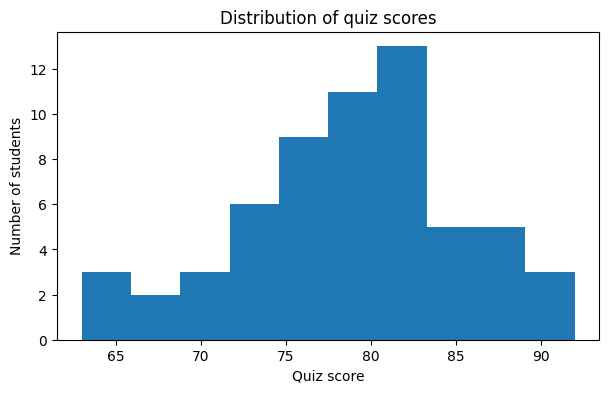

有效成績筆數： 60


In [2]:
# 以英文標籤避免 Colab 缺中文字型；圖形後呼叫 show
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10)  # TODO：以 quiz_score 的非缺失資料畫 bins=10 的直方圖
plt.title("Distribution of quiz scores")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()
print("有效成績筆數：", df["quiz_score"].count())


### ✅ 作業 04-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert df["quiz_score"].notna().sum() == 60
print("請人工檢查上方直方圖的標題、軸及 10 個分箱。")


請人工檢查上方直方圖的標題、軸及 10 個分箱。


## 📝 學生作業 04-Q2｜AI 查詢與作答：圖形解讀
**任務：**直方圖 bins 改變時，為何外觀會改變？是否代表資料本身改變？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 04-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：我是 Python 與資料分析初學者。請解釋直方圖分箱與盒鬚圖各能回答什麼問題，並說明離群點不一定是錯誤。請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
- AI 回答重點（請自行整理）：直方圖改變 bins 的影響：直方圖是將連續數值切分成多個區間（分箱）來計算各區間的人數；當 bins 數量改變時，每個區間的寬度與落入各箱的人數會重新歸類，因此外觀形狀會改變，但底層原始資料與總人數完全沒有變動。   直方圖 vs. 盒鬚圖與離群點判斷：直方圖適合觀察資料整體的分布形狀（如集中趨勢、單峰或偏態）；盒鬚圖適合快速比較中位數、四分位距（IQR）與標示潛在離群點。圖上的離群點僅代表「數值偏離多數資料」，可能是真實存在的極端案例（例如真的有人每天滑手機 15 小時），必須回頭查核業務規則才能判斷是否為輸入錯誤。   
- 我的理解與具體例子：就像把 60 位學生的成績分成「每 3 分一組（10 箱）」或「每 6 分一組（5 箱）」，分組變粗時長條圖看起來會比較平滑，但全班 60 個人的分數一個字都沒改，加總依然是 60 人。另外，在 screen_time_hours 的盒鬚圖中上方出現一個獨立圓點（15 小時），它能提醒我們去檢查那筆資料，而不能直接當成錯誤刪掉。
- 查證來源／方式及日期（無法查證請註明）：對照本單元教材 4.2 節、4.3 節與延伸示範程式碼執行結果（確認 bins=5 與 bins=10 時 counts.sum() 皆為 60）（2026-11-13 查證）。
- 我檢查或修正 AI 回答的地方：Gemini 解釋了分箱與離群值的統計意義，我對照延伸示範的 np.histogram() 輸出結果，確認不論分 5 箱或 10 箱，各箱人數加總皆等於有效筆數 60 筆，驗證原始資料未改變。


## 4.3 盒鬚圖與極端值
盒體反映四分位區間；獨立點是依繪圖規則標示的可能離群值，不等於資料一定錯誤。
**試一試：**將直方圖分箱改為 5，解釋圖形外觀為何改變。


In [ ]:
# dropna 避免缺失值影響繪圖，資料並未從 df 刪除
plt.figure(figsize=(5, 4))
plt.boxplot(df["screen_time_hours"].dropna())
plt.title("Screen time")
plt.ylabel("Hours")
plt.show()
print("大於 10 小時：", (df["screen_time_hours"] > 10).sum())


## 延伸示範：分箱前後數據不變
相同資料用不同 bins 切分，外觀會不同。學生須檢查各箱人數加總與原本有效筆數是否一致，避免把分箱造成的視覺差異誤認為資料變化。


In [ ]:
# numpy 的 histogram 回傳各箱人數及邊界；檢查加總是否一致
valid_scores = df["quiz_score"].dropna()
for bins in [5, 10]:
    counts, edges = np.histogram(valid_scores, bins=bins)
    print("分箱數", bins, "各箱人數", counts, "加總", counts.sum())
    assert counts.sum() == len(valid_scores)


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。


## 🎯 學生小任務 MA｜資料健檢與圖表
**涵蓋：**任務 1～4。這是需要獨立完成、可繳交的整合成果。

### 任務要求
使用 df，以程式列出資料形狀、各欄缺失數、超過 10 小時的筆數；再繪製 quiz_score 直方圖。用文字說明一項品質問題、一項圖表觀察及一項資料限制。不可修改 df。

### 可使用的 AI 提示詞
```text
我是 Python 初學者，請協助我完成以下資料分析小任務：
請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。
請拆成小步驟，提供繁體中文教學註解、預期輸出應如何檢查，並提醒不能從這份模擬資料推論因果。
```

### 執行與交付
- 在下一個程式儲存格自行填入程式，先執行本 Notebook 上方的資料準備及必要 cell。若需要更多儲存格可以自行新增。
- 輸出應保留在 Notebook 中；在後面的文字區填寫實際數字與自己的解釋。
- **工具提示：**df.shape、df.isna()、布林篩選、plt.hist。
- 至少記錄一項實際檢查及一項資料限制。交付完成後的 `.ipynb`，含程式、輸出及 AI 使用紀錄。


In [4]:
# 學生小任務 MA：請在此撰寫你的程式
# 執行前先確認上方資料準備與必要 cell 已執行；可新增其他程式 cell。
# TODO：依任務要求加入程式；完成後執行並保留輸出。

# 學生小任務 MA：資料健檢與圖表
# 輸入：原始模擬資料表 df（不進行任何修改）

# 1. 列出資料形狀（列數, 欄數）
print("1. 資料形狀（列數, 欄數）：", df.shape)

# 2. 列出各欄位缺失值數量
print("\n2. 各欄位缺失值數量：")
print(df.isna().sum())

# 3. 計算螢幕時間（screen_time_hours）超過 10 小時的筆數
over_10_count = (df["screen_time_hours"] > 10).sum()
print("\n3. 螢幕時間超過 10 小時的筆數：", over_10_count)

# 4. 繪製 quiz_score 直方圖（排除缺失值，分 10 箱）
plt.figure(figsize=(7, 4))
plt.hist(df["quiz_score"].dropna(), bins=10, edgecolor="black")
plt.title("Distribution of quiz scores (Task MA)")
plt.xlabel("Quiz score")
plt.ylabel("Number of students")
plt.show()

# 5. 驗證：確認原始 df 筆數與欄位未受更動
assert df.shape == (60, 7)
print("驗證通過：原始 df 維持 60 列、7 欄，未被修改。")


### ✍️ 小任務 MA｜結果與檢核（請雙擊填寫）
- 問題及使用的資料／欄位：對學生學習模擬資料表 df 進行基礎資料健檢並觀察成績分布，使用的欄位包含全表欄位（檢查形狀與缺失值）、screen_time_hours（檢查超出案例規格的異常值）與 quiz_score（繪製小考成績分布直方圖）。
- 實際輸出與至少一項依據數字的觀察：資料形狀為 (60, 7)（共 60 筆學生紀錄、7 個欄位）；缺失值檢查發現 sleep_hours 有 2 筆缺失（其餘欄位皆為 0 筆缺失）；screen_time_hours 超過 10 小時的有 1 筆（數值為 15.0 小時）。
- 圖表或模型結果的解讀（依任務要求）：從 quiz_score 直方圖（分 10 箱）可觀察到，60 位學生的成績介於 63 分到 92 分之間，整體呈單峰分布，多數學生集中在 75 分至 83 分區間（中位數為 80.0 分、平均數為 78.8 分），極低分與極高分的人數較少。
- 資料品質、模擬資料或評估限制：本資料共有兩項品質問題需標記待查（sleep_hours 缺失 2 筆、screen_time_hours 異常高於 10 小時 1 筆）。此外，本資料為透過固定隨機種子與公式生成的 60 筆模擬紀錄，且缺失值與 15 小時異常值是在計分後才故意置入，因此不能用來推論真實學生的學習狀況或變數間的因果關係。
- 驗證方法與結果：在程式最後加入 assert df.shape == (60, 7) 斷言檢查，並核對 df["quiz_score"].count() 為 60、直方圖各箱人數總和等於 60，確認全程僅做唯讀查詢與繪圖，完全未修改原始 df。
- AI 工具、實際提示詞、人工修改與遇到的問題：我是 Python 初學者，請協助我完成以下資料分析小任務：請幫我規劃 pandas 的資料健檢與成績直方圖：顯示形狀、缺失數與螢幕大於10的筆數，保留原始 df，加繁中註解並提供驗證方式，不要捏造結果。Gemini 提供了標準健檢語法，我人工加上 edgecolor="black" 讓直方圖分箱邊界更清晰，並補上 assert 斷言驗證資料完整性；執行過程順利無報錯。
- 重新執行是否成功及環境或檔案需求：已在 Google Colab 執行「重新啟動工作階段並全部執行」，從「共用資料準備」至「小任務 MA」皆順利執行成功並保留完整圖表與數字輸出，無需額外外部檔案即可獨立重現結果。